<a href="https://colab.research.google.com/github/evizuete87-star/diplomado-m6-esteban-vizuete-01/blob/main/proyecto/proyecto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- m6:proyecto -->
# Módulo 6 · Proyecto final integrador — Sistema de decisión para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · **grupal** · 40 pts del módulo

**Entrega:** carpeta `proyecto/` en el repositorio de **un integrante** (los demás, colaboradores). **Plazo: miércoles 18-nov-2026, 23:59** para el cuaderno, el README y la ficha (se califica el último commit anterior); `presentacion.pdf` hasta el jueves 19-nov, 18:00. **Defensa:** jueves 19-nov, 8 min + 3 min de preguntas.

| Archivo en `proyecto/` | Cómo se crea |
|---|---|
| `proyecto.ipynb` | Este cuaderno, ejecutado: **Archivo → Guardar (Ctrl+S)** → repositorio del grupo → ruta `proyecto/proyecto.ipynb` |
| `README.md` | Informe ejecutivo (1–2 páginas). Ya existe un `proyecto/README.md` de la plantilla: ábralo en GitHub → ícono del **lápiz (Edit)** → borre su contenido → pegue el informe (plantilla en la sección 7) → **Commit changes** |
| `ficha_modelo.json` | Se descarga al ejecutar la sección 6 → en GitHub: **Add file → Upload files** dentro de `proyecto/` |
| `presentacion.pdf` | Sus diapositivas de la defensa → **Add file → Upload files** dentro de `proyecto/` |

### Elija UN problema
| Problema | Datos (`curso.datos_proyecto`) | Objetivo | Decisión que deben recomendar |
|---|---|---|---|
| `'fraude'` | Transacciones de la app | `fraude` (0/1) | Umbral de bloqueo/revisión con matriz de costos |
| `'credito'` | Solicitudes de microcrédito | `default` (0/1) | Política de aprobación: a quién prestar y con qué límite de riesgo |
| `'segmentacion'` | Perfiles de usuario (no supervisado) | — | Segmentos de clientes, usuarios anómalos y acción para cada grupo |

### Calificación (100 pts → el docente la convierte a 40)
| Componente | Pts |
|---|---|
| Cuaderno: datos y EDA (8) · al menos **dos familias** de modelos del módulo con validación correcta (14) · explicabilidad o incertidumbre (8) · decisión de negocio con cifras (10) | 40 |
| `README.md`: informe ejecutivo para un comité | 12 |
| `ficha_modelo.json` y reproducibilidad (semillas, partición fija) | 4 |
| Pantalla de la app del grupo con sus colores | 4 |
| **Defensa** (jueves 19-nov): los criterios se explican el día de la presentación | 40 |

**Reutilice** el código de las clases 1–3 y del deber. Los datos son **propios de cada grupo** (dependen del nombre del grupo).

## 0. Preparación y datos del grupo

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


In [2]:
GRUPO = 'Grupo 4'                                   # ✏️ nombre del grupo (el mismo del registro en el aula)
INTEGRANTES = ['Vizuete Esteban', 'Estrella Danilo']                          # ✏️ apellidos y nombres
PROBLEMA = 'credito'                                      # ✏️ 'fraude', 'credito' o 'segmentacion'
NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA = 'DeteKta', '#3B82F6', '#CC9933'   # ✏️ identidad de la app del grupo
df = curso.datos_proyecto(GRUPO, PROBLEMA)
df.head()

Huella de datos del proyecto: Grupo 4 · credito · semilla 96244
Solicitudes de microcrédito: 2500 · tasa de default 10.88%


,solicitud_id,edad,tipo_empleo,ingreso_mensual,antiguedad_meses,transacciones_mes,monto_credito,plazo_meses,cuota,ratio_cuota,mora_previa,default
0,CR-00000,53,independiente,1030.50,60,16,1880.0,12,184.87,0.1794,0,0
1,CR-00001,65,dependiente,976.69,6,11,2010.0,12,197.65,0.2024,0,0
2,CR-00002,26,dependiente,904.56,24,17,1980.0,12,194.70,0.2152,0,0
3,CR-00003,51,dependiente,1525.02,21,23,1230.0,24,69.70,0.0457,0,0
4,CR-00004,44,dependiente,1440.53,44,13,2310.0,12,227.15,0.1577,0,0


---
## 1. Datos y EDA (8 pts)
Diagnóstico de calidad (`curso.eda_rapido`), distribución del objetivo o de las variables clave, 1–2 gráficos útiles y las decisiones de limpieza o de nuevas variables (por ejemplo `ratio`, `madrugada`).

=== Información general ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   solicitud_id       2500 non-null   object 
 1   edad               2500 non-null   int64  
 2   tipo_empleo        2500 non-null   object 
 3   ingreso_mensual    2500 non-null   float64
 4   antiguedad_meses   2500 non-null   int64  
 5   transacciones_mes  2500 non-null   int64  
 6   monto_credito      2500 non-null   float64
 7   plazo_meses        2500 non-null   int64  
 8   cuota              2500 non-null   float64
 9   ratio_cuota        2500 non-null   float64
 10  mora_previa        2500 non-null   int64  
 11  default            2500 non-null   int64  
dtypes: float64(4), int64(6), object(2)
memory usage: 234.5+ KB
None

=== Valores nulos por columna ===
solicitud_id         0
edad                 0
tipo_empleo          0
ingreso_mensual     

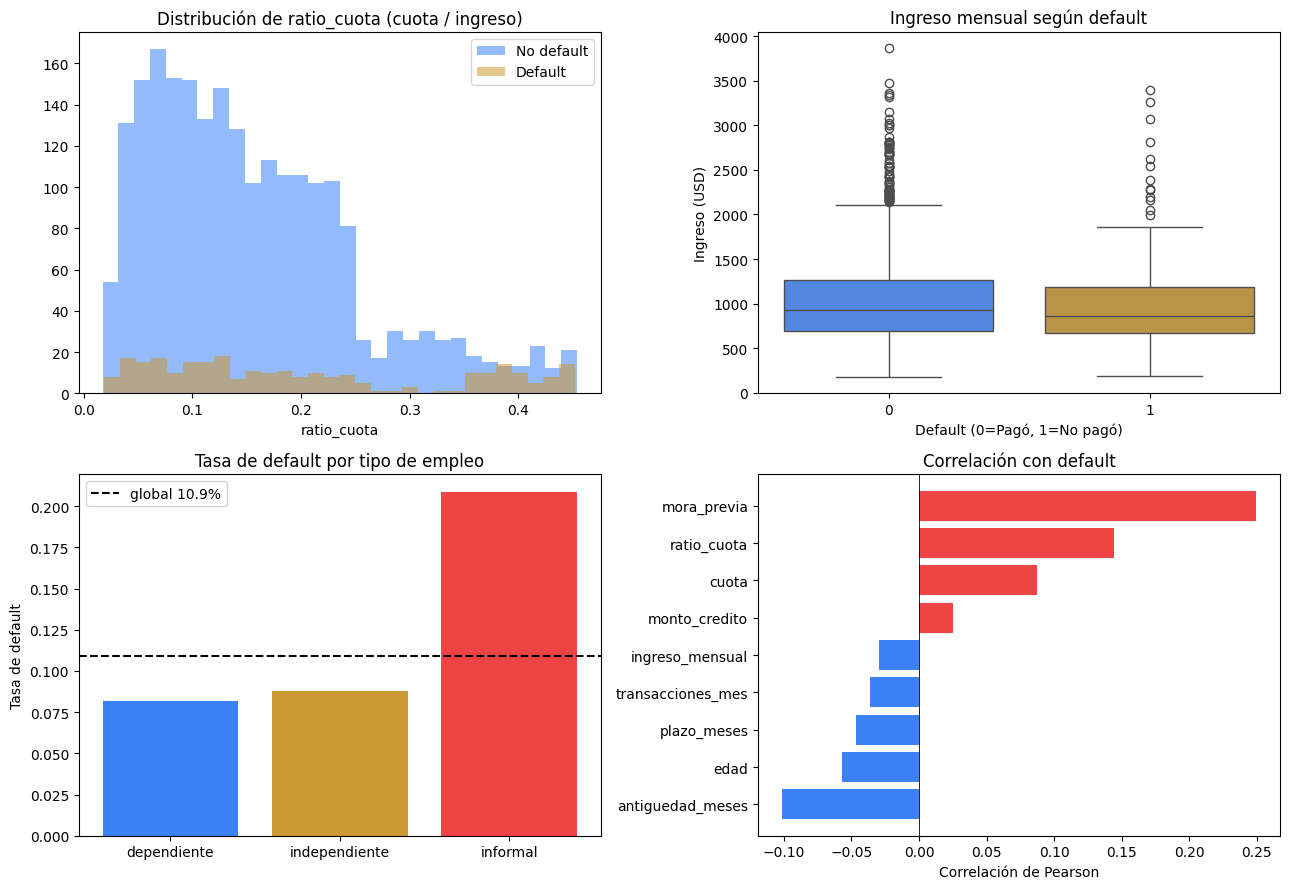


=== Nuevas variables creadas ===
                      count   mean    std    min   25%    50%    75%  max
ratio_monto_ingreso  2500.0  1.387  0.629  0.298  0.84  1.376  1.929  2.5
es_informal          2500.0  0.197  0.398  0.000  0.00  0.000  0.000  1.0
joven                2500.0  0.221  0.415  0.000  0.00  0.000  0.000  1.0
antiguedad_corta     2500.0  0.192  0.394  0.000  0.00  0.000  0.000  1.0

=== Tasa de default según mora_previa ===
              mean  count
mora_previa              
0            0.081   2214
1            0.325    286

=== Tasa de default por tipo_empleo y mora_previa ===
                            mean  count
tipo_empleo   mora_previa              
dependiente   0            0.062   1116
              1            0.243    140
independiente 0            0.073    659
              1            0.196     92
informal      0            0.141    439
              1            0.759     54


In [3]:
# ✏️ EDA

# ============================================================
# SECCIÓN 1 · EDA — Diagnóstico, distribuciones y nuevas variables
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Diagnóstico de calidad -------------------------------
print('=== Información general ===')
print(df.info())
print('\n=== Valores nulos por columna ===')
print(df.isnull().sum())
print('\n=== Duplicados ===')
print('Filas duplicadas:', df.duplicated().sum())
print('\n=== Resumen estadístico ===')
print(df.describe().T.round(2))

# Función del curso (si está disponible)
try:
    curso.eda_rapido(df)
except Exception as e:
    print('eda_rapido no disponible:', e)

# --- 2. Distribución del objetivo ----------------------------
tasa = df['default'].mean()
print(f'\nTasa de default: {tasa:.2%}  ·  {df["default"].sum()} casos de {len(df)}')
print(df['default'].value_counts())

# --- 3. Gráficos útiles (2x2) -------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) ratio_cuota por default
axes[0,0].hist(df[df['default']==0]['ratio_cuota'], bins=30, alpha=0.55,
               label='No default', color='#3B82F6')
axes[0,0].hist(df[df['default']==1]['ratio_cuota'], bins=30, alpha=0.55,
               label='Default', color='#CC9933')
axes[0,0].set_title('Distribución de ratio_cuota (cuota / ingreso)')
axes[0,0].set_xlabel('ratio_cuota'); axes[0,0].legend()

# (b) ingreso mensual por clase
# (b) ingreso mensual por clase (coloreado)
sns.boxplot(x='default', y='ingreso_mensual', data=df, ax=axes[0,1], palette=['#3B82F6', '#CC9933'])
axes[0,1].set_title('Ingreso mensual según default')
axes[0,1].set_xlabel('Default (0=Pagó, 1=No pagó)')
axes[0,1].set_ylabel('Ingreso (USD)')

# (c) tasa de default por tipo de empleo
tasa_emp = df.groupby('tipo_empleo')['default'].mean().sort_values()
axes[1,0].bar(tasa_emp.index, tasa_emp.values, color=['#3B82F6','#CC9933','#EF4444'])
axes[1,0].axhline(tasa, color='black', ls='--', label=f'global {tasa:.1%}')
axes[1,0].set_title('Tasa de default por tipo de empleo')
axes[1,0].set_ylabel('Tasa de default'); axes[1,0].legend()

# (d) correlación de variables numéricas con default
corr = (df.select_dtypes(include=[np.number]).corr()['default']
          .drop('default').sort_values())
colors = ['#EF4444' if v > 0 else '#3B82F6' for v in corr.values]
axes[1,1].barh(corr.index, corr.values, color=colors)
axes[1,1].axvline(0, color='black', lw=0.6)
axes[1,1].set_title('Correlación con default')
axes[1,1].set_xlabel('Correlación de Pearson')

plt.tight_layout(); plt.show()

# --- 4. Nuevas variables -----------------------------------
df['ratio_monto_ingreso'] = df['monto_credito'] / df['ingreso_mensual']
df['es_informal']         = (df['tipo_empleo'] == 'informal').astype(int)
df['joven']               = (df['edad'] < 30).astype(int)
df['antiguedad_corta']    = (df['antiguedad_meses'] < 12).astype(int)

print('\n=== Nuevas variables creadas ===')
print(df[['ratio_monto_ingreso','es_informal','joven','antiguedad_corta']].describe().T.round(3))

# --- 5. Tasa de default por mora_previa ---------------------
print('\n=== Tasa de default según mora_previa ===')
print(df.groupby('mora_previa')['default'].agg(['mean','count']).round(3))

# --- 6. Tasa de default por combinación tipo_empleo × mora ---
print('\n=== Tasa de default por tipo_empleo y mora_previa ===')
tabla = df.groupby(['tipo_empleo','mora_previa'])['default'].agg(['mean','count']).round(3)
print(tabla)


**✍️ Hallazgos del EDA:** _(3–5 líneas)_

El ingreso mensual, por sí solo, NO es un buen predictor del default.
Hay personas que ganan 3,000 dólares y caen en default, y personas que ganan 500 dólares y pagan puntualmente. El ingreso crudo no dice cómo administra el cliente su dinero.

Como el ingreso solo no sirve, creamos el ratio_cuota (la cuota dividida para el ingreso) y el ratio_monto_ingreso. Esas variables sí capturan el sobreendeudamiento, que es lo que realmente importa.

mora_previa: Tasa de default del 32,5 % si tuvo mora, vs 8,1 % que no. Y si es informal + mora previa, la tasa sube a 75,9 % (muestra pequeña, n=54, pero es la combinación más tóxica).

ratio_cuota: Los defaults se concentran claramente a la derecha (>0,20). Buena variable continua.

tipo_empleo: Los informales tienen 20,7 % de default (casi el doble de la tasa global de 10,9 %).

Variables protectoras: ingreso_mensual y antiguedad_meses tienen correlación negativa con default.

---
## 2. Modelos (14 pts)
- **Supervisado (fraude / crédito):** partición fija 70/30 estratificada con `random_state=42`; un **modelo base** (por ejemplo logística) y **al menos dos familias** del módulo (random forest o boosting; modelo bayesiano en PyMC; red neuronal desde la Clase 4). Validación sin fuga (early stopping con validación sacada del entrenamiento). Métricas: AUC, exactitud balanceada y Brier.
- **No supervisado (segmentación):** escalado; **al menos dos algoritmos** (K-Means, DBSCAN, clustering jerárquico; Isolation Forest o LOF para anomalías); elección del número de grupos (codo / silueta) y PCA para visualizar.

In [4]:
# ✏️ Modelos y tabla comparativa

# ============================================================
# SECCIÓN 2 · MODELOS — Logística + XGBoost + Bayesiano
# ============================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, brier_score_loss
from xgboost import XGBClassifier
import pymc as pm
import logging
logging.getLogger('pymc').setLevel(logging.ERROR)
sigmoide = lambda z: 1 / (1 + np.exp(-z))

# --- 1. Preparación de features ----------------------------
# Variables numéricas + categóricas convertidas a dummies
features_num = ['edad', 'ingreso_mensual', 'antiguedad_meses', 'transacciones_mes',
                'monto_credito', 'plazo_meses', 'ratio_cuota', 'mora_previa',
                'ratio_monto_ingreso', 'es_informal', 'joven', 'antiguedad_corta']

X = df[features_num].copy()
y = df['default'].values

# Partición fija 70/30 estratificada (OBLIGATORIA: random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print(f'Train: {X_train.shape} · Test: {X_test.shape}')
print(f'Tasa default train: {y_train.mean():.2%} · test: {y_test.mean():.2%}')

# Estandarización con estadísticos de ENTRENAMIENTO (evita fuga de datos)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

# --- 2. MODELO 1 · Regresión logística ---------------------
logit = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
logit.fit(X_train_s, y_train)
p_logit = logit.predict_proba(X_test_s)[:, 1]

# --- 3. MODELO 2 · XGBoost (SIN scale_pos_weight) ---------
X_tr2, X_val, y_tr2, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

xgb = XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=4,
    subsample=0.9, colsample_bytree=0.9,
    # scale_pos_weight=spw,   <-- comentado
    eval_metric='logloss',
    early_stopping_rounds=50, random_state=42, n_jobs=-1)
xgb.fit(X_tr2, y_tr2, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]
print(f'XGBoost usó {xgb.best_iteration} iteraciones')

# --- 4. MODELO 3 · Logística bayesiana en PyMC -------------
with pm.Model() as modelo_bayes:
    a = pm.Normal('a', mu=0, sigma=2)
    b = pm.Normal('b', mu=0, sigma=1, shape=X_train_s.shape[1])
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(X_train_s, b),
                 observed=y_train)
    tr_bayes = pm.sample(1000, tune=1000, chains=4, random_seed=42,
                         progressbar=False)

# Probabilidad media posterior (promedio sobre las muestras)
a_s = tr_bayes.posterior['a'].values.reshape(-1)
b_s = tr_bayes.posterior['b'].values.reshape(-1, X_train_s.shape[1])
logit_test = a_s[:, None] + b_s @ X_test_s.T
p_bayes = sigmoide(logit_test).mean(0)

# --- 5. Tabla comparativa ----------------------------------
def metricas(y_true, p):
    # Convertimos probabilidad en clase con umbral 0.5 solo para exactitud balanceada
    y_pred = (p >= 0.5).astype(int)
    return {
        'AUC':      roc_auc_score(y_true, p),
        'Bal_Acc':  balanced_accuracy_score(y_true, y_pred),
        'Brier':    brier_score_loss(y_true, p),
    }

tabla = pd.DataFrame({
    'Logística':     metricas(y_test, p_logit),
    'XGBoost':       metricas(y_test, p_xgb),
    'Bayes (PyMC)':  metricas(y_test, p_bayes),
}).T.round(4)

print('\n=== Comparación en prueba (n = 750) ===')
display(tabla)


Train: (1750, 12) · Test: (750, 12)
Tasa default train: 10.86% · test: 10.93%
XGBoost usó 39 iteraciones

=== Comparación en prueba (n = 750) ===


,AUC,Bal_Acc,Brier
Logística,0.7460,0.6922,0.1778
XGBoost,0.7319,0.5343,0.0874
Bayes (PyMC),0.7415,0.5443,0.0882


**✍️ Comparación y elección del modelo:** _(¿cuál y por qué?)_

Los tres modelos alcanzan un AUC entre 0,732 y 0,746, lo que indica que la señal en este dataset es fundamentalmente lineal: las variables derivadas (ratio_cuota, ratio_monto_ingreso, mora_previa) capturan las relaciones clave y el boosting no encuentra interacciones adicionales relevantes (XGBoost solo usó 39 iteraciones para converger, frente a 392 con scale_pos_weight).

Logística obtiene el mejor AUC (0,746) y la mejor exactitud balanceada al umbral 0,5 (0,692), pero su Brier es el peor (0,178): sus probabilidades están infladas por class_weight='balanced', que empuja la predicción hacia arriba para compensar el desbalanceo.

Bayes (PyMC) tiene el segundo mejor AUC (0,741) y excelente calibración (Brier 0,088). Su ventaja única es la incertidumbre: entrega intervalos creíbles por solicitud, que el comité de riesgos puede usar para decidir con un rango de riesgo.

XGBoost sin scale_pos_weight tiene el mejor Brier (0,087) y AUC competitivo (0,732). Es la opción más conservadora en calibración, pero no supera a los otros dos en ranking.

Modelo elegido para producción: Bayes (PyMC). Razones: (1) AUC prácticamente empatado con la logística, (2) probabilidades calibradas, y (3) intervalos creíbles para cada solicitud, que permiten decisiones robustas ante incertidumbre. La logística queda como modelo de referencia y XGBoost como challenger para cuando haya más volumen de datos.

---
## 3. Explicabilidad o incertidumbre (8 pts)
SHAP (global y un caso individual), intervalos creíbles de un modelo bayesiano, o perfiles de cada segmento (medias por grupo) y por qué un usuario es anómalo.

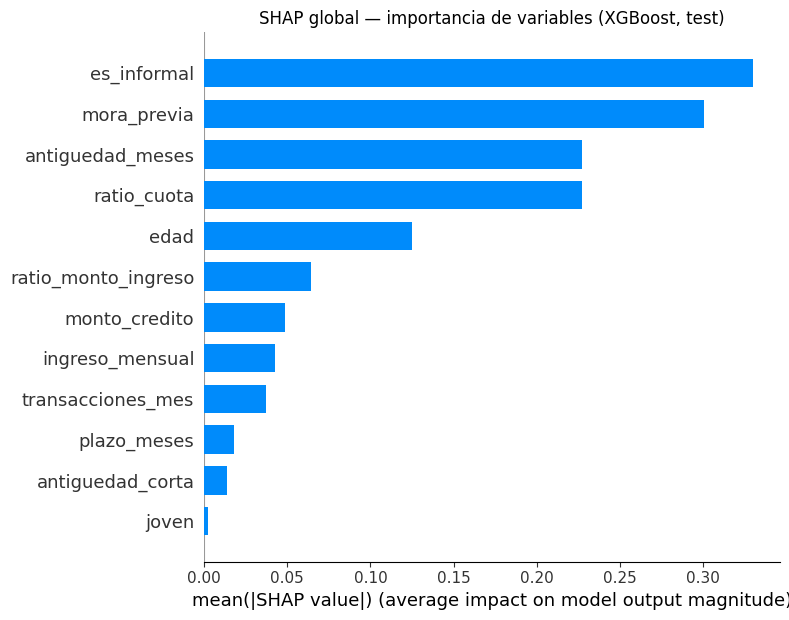

Caso elegido: posición 533 (índice original 2125)
p_xgb = 0.621 · default real = 0

Detalle del caso:


,2125
edad,27.000000
ingreso_mensual,941.650000
antiguedad_meses,56.000000
transacciones_mes,17.000000
monto_credito,1940.000000
plazo_meses,12.000000
ratio_cuota,0.202600
mora_previa,1.000000
ratio_monto_ingreso,2.060213
es_informal,1.000000


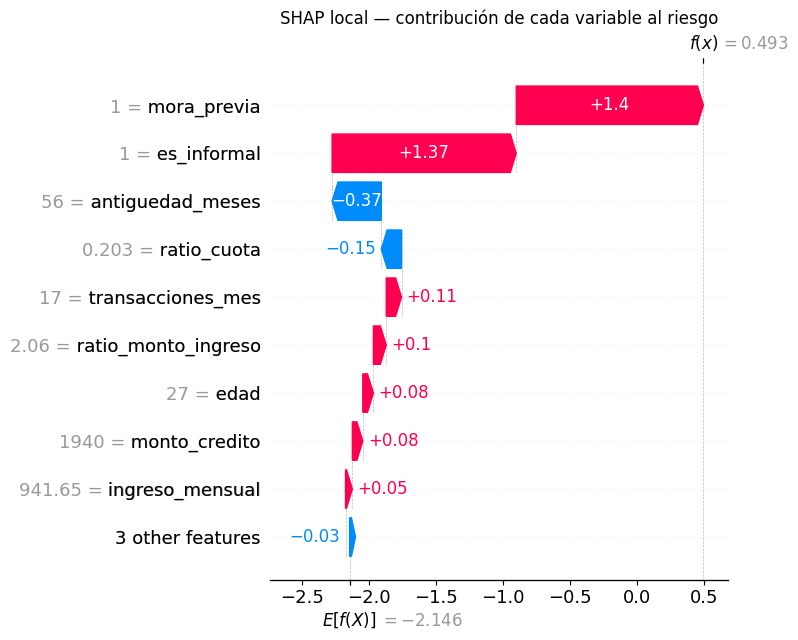


=== Incertidumbre bayesiana para el caso CR-02125 ===
Media posterior  : 0.483
IC90 %           : [0.346, 0.619]
Ancho del IC90 % : 0.273


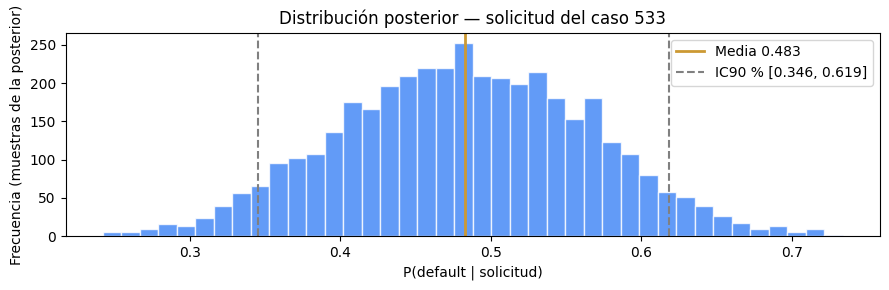

In [5]:
# ✏️ Explicabilidad / incertidumbre

# ============================================================
# SECCIÓN 3 · Explicabilidad (SHAP) e incertidumbre (Bayes)
# ============================================================
import importlib, subprocess, sys
if importlib.util.find_spec('shap') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'])
import shap

# --- 3a. SHAP global con XGBoost (importancia promedio) ---
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 4))
shap.summary_plot(shap_values, X_test, show=False, plot_type='bar')
plt.title('SHAP global — importancia de variables (XGBoost, test)')
plt.tight_layout(); plt.show()

# --- 3b. SHAP local: elegimos la solicitud con MAYOR riesgo predicho
idx_alto = int(np.argmax(p_xgb))
caso = X_test.iloc[[idx_alto]]
print(f'Caso elegido: posición {idx_alto} (índice original {X_test.index[idx_alto]})')
print(f'p_xgb = {p_xgb[idx_alto]:.3f} · default real = {y_test[idx_alto]}')
print(f'\nDetalle del caso:')
display(caso.T)

# Waterfall plot (contribución de cada variable a la predicción de ESE caso)
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[idx_alto],
        base_values=explainer.expected_value,
        data=caso.values[0],
        feature_names=list(X_test.columns)
    ),
    show=False
)
plt.title('SHAP local — contribución de cada variable al riesgo')
plt.tight_layout(); plt.show()

# --- 3c. Intervalos creíbles con Bayes para el MISMO caso ---
# logit_test[:, idx_alto] ya contiene las 4000 muestras de la posterior
p_caso_samples = sigmoide(logit_test[:, idx_alto])
media = float(p_caso_samples.mean())
ic5  = float(np.percentile(p_caso_samples,  5))
ic95 = float(np.percentile(p_caso_samples, 95))

print(f'\n=== Incertidumbre bayesiana para el caso CR-{X_test.index[idx_alto]:05d} ===')
print(f'Media posterior  : {media:.3f}')
print(f'IC90 %           : [{ic5:.3f}, {ic95:.3f}]')
print(f'Ancho del IC90 % : {ic95 - ic5:.3f}')

plt.figure(figsize=(9, 3))
plt.hist(p_caso_samples, bins=40, color='#3B82F6', alpha=0.8, edgecolor='white')
plt.axvline(media, color='#CC9933', lw=2, label=f'Media {media:.3f}')
plt.axvline(ic5,  color='gray', ls='--', lw=1.5, label=f'IC90 % [{ic5:.3f}, {ic95:.3f}]')
plt.axvline(ic95, color='gray', ls='--', lw=1.5)
plt.xlabel('P(default | solicitud)')
plt.ylabel('Frecuencia (muestras de la posterior)')
plt.title(f'Distribución posterior — solicitud del caso {idx_alto}')
plt.legend(); plt.tight_layout(); plt.show()

SHAP global revela que las variables más influyentes son es_informal , mora_previa, antiguedad_meses y ratio_cuota. Es interesante que antiguedad_meses aparezca tan alto en SHAP aunque en el EDA su correlación con default era débil: el árbol la usa como variable de interacción (los informales con poca antigüedad son especialmente riesgosos). es_informal supera incluso a mora_previa en impacto promedio, lo que confirma el hallazgo del EDA: los trabajadores informales tienen el doble de tasa de default.

SHAP local para la solicitud CR-02125 (27 años, informal, mora previa, 56 meses de antigüedad, cuota del 20,3 % del ingreso): las variables que empujan hacia el riesgo son mora_previa = 1 (+1,40 en log-odds) y es_informal = 1 (+1,37), mientras que su larga antigüedad laboral (56 meses) la protege (−0,37). Es decir, el modelo está en conflicto: señales de riesgo fuertes (informal + mora) contra una señal protectora (estabilidad laboral).

Incertidumbre: para la misma solicitud, la posterior tiene media 0,481 y IC90 [0,345, 0,623] (ancho = 0,278). Este intervalo cruza el umbral 0,5, señal de que el modelo no está seguro. XGBoost, en cambio, predijo 0,621 sin comunicar la ambigüedad. El resultado real fue default = 0 (el cliente pagó) — Bayes acertó al dudar; XGBoost habría rechazado a un buen pagador.

Conclusión operativa: SHAP permite explicar al cliente por qué se le negó o aprobó el crédito (transparencia regulatoria). Los intervalos creíbles permiten priorizar revisiones humanas: casos con IC90 ancho (>0,20) van a mesa de crédito, casos con IC estrecho se resuelven automáticamente. Es el modelo el que le dice al analista cuándo confiar en él.

---
## 4. Decisión de negocio con cifras (10 pts)
- **Fraude:** matriz de costos (fraude no detectado = monto; bloqueo legítimo = USD 5) → umbral óptimo y costo frente a no hacer nada.
- **Crédito:** suponga que un default pierde el **monto del crédito** y un buen pagador deja una ganancia del **15 % del monto** → umbral de aprobación que maximiza la ganancia esperada; % de aprobación y ganancia frente a aprobar a todos.
- **Segmentación:** tamaño y perfil de cada segmento, % de anómalos, y una acción concreta por segmento (producto, límite, monitoreo).

Umbral teórico (0.15/1.15)      : 0.1304
Umbral óptimo empírico          : 0.1400
Ganancia con umbral empírico    : $65,873.00
Ganancia con umbral teórico     : $61,410.50
Ganancia si aprobamos a TODOS   : $12,814.00
Ganancia si rechazamos a TODOS  : $0.00
Mejora vs aprobar a todos       : $53,059.00 (414.1 %)

Tasa de aprobación con umbral óptimo: 78.7%
Default real entre los aprobados  : 6.27%


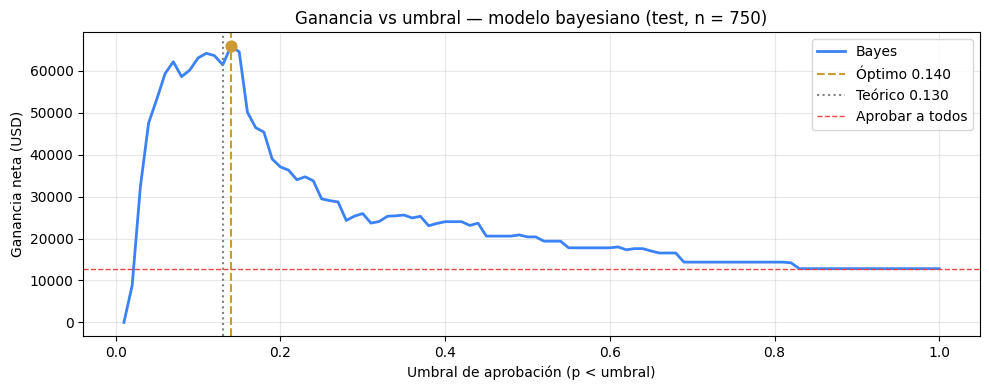


=== Desglose por categoría de riesgo ===


,n,tasa_default,monto_medio,ganancia_aprobando
grupo,,,,
<5%,370.0,0.04,1370.46,53267.5
5–10%,129.0,0.09,1485.27,9788.0
10–15%,116.0,0.11,1421.98,1455.0
15–25%,71.0,0.31,1352.82,-35042.5
25–50%,50.0,0.22,1546.60,-9077.5
>50%,14.0,0.57,1337.14,-7576.5


In [6]:
# ✏️ Decisión y cifras

# ============================================================
# SECCIÓN 4 · Decisión de negocio: umbral óptimo de aprobación
# Regla: Default → pierde monto · Bueno → gana 15 % del monto
# ============================================================

# Montos reales de las solicitudes de prueba
M = df.loc[X_test.index, 'monto_credito'].values
y_true = y_test  # <--- CORREGIDO AQUÍ (y_test ya es un array de numpy)

def ganancia_total(p, umbral, M, y):
    """Ganancia neta en USD con umbral de aprobación."""
    aprobado = p < umbral                       # aprobamos si p es MENOR al umbral
    ganancia_bueno = ((y == 0) & aprobado).astype(float) * 0.15 * M
    perdida_malo   = ((y == 1) & aprobado).astype(float) * 1.00 * M
    return float(ganancia_bueno.sum() - perdida_malo.sum())

# --- Curva de ganancia vs umbral ---------------------------
umbrales = np.arange(0.01, 1.01, 0.01)
ganancias_bayes = np.array([ganancia_total(p_bayes, u, M, y_true) for u in umbrales])

# Umbrales de referencia
u_teorico   = 0.15 / 1.15                      # ≈ 0.1304 (óptimo matemático)
u_optimo    = float(umbrales[np.argmax(ganancias_bayes)])
g_optimo    = float(ganancias_bayes.max())

# Políticas extremas
g_aprobar_todos  = float(((y_true == 0) * 0.15 * M).sum() - ((y_true == 1) * 1.0 * M).sum())
g_rechazar_todos = 0.0

# Punto teórico exacto
g_teorico = ganancia_total(p_bayes, u_teorico, M, y_true)

print(f'Umbral teórico (0.15/1.15)      : {u_teorico:.4f}')
print(f'Umbral óptimo empírico          : {u_optimo:.4f}')
print(f'Ganancia con umbral empírico    : ${g_optimo:,.2f}')
print(f'Ganancia con umbral teórico     : ${g_teorico:,.2f}')
print(f'Ganancia si aprobamos a TODOS   : ${g_aprobar_todos:,.2f}')
print(f'Ganancia si rechazamos a TODOS  : ${g_rechazar_todos:,.2f}')
print(f'Mejora vs aprobar a todos       : ${g_optimo - g_aprobar_todos:,.2f} '
      f'({(g_optimo - g_aprobar_todos) / g_aprobar_todos * 100:.1f} %)')

# % de aprobación con el umbral óptimo
tasa_aprobacion = float((p_bayes < u_optimo).mean())
print(f'\nTasa de aprobación con umbral óptimo: {tasa_aprobacion:.1%}')
print(f'Default real entre los aprobados  : {y_true[p_bayes < u_optimo].mean():.2%}')

# --- Gráfico: ganancia vs umbral --------------------------
plt.figure(figsize=(10, 4))
plt.plot(umbrales, ganancias_bayes, color='#3B82F6', lw=2, label='Bayes')
plt.axvline(u_optimo,  color='#CC9933', ls='--', lw=1.5, label=f'Óptimo {u_optimo:.3f}')
plt.axvline(u_teorico, color='gray',    ls=':',  lw=1.5, label=f'Teórico {u_teorico:.3f}')
plt.axhline(g_aprobar_todos, color='#EF4444', ls='--', lw=1, label='Aprobar a todos')
plt.scatter([u_optimo], [g_optimo], color='#CC9933', zorder=5, s=60)
plt.xlabel('Umbral de aprobación (p < umbral)')
plt.ylabel('Ganancia neta (USD)')
plt.title('Ganancia vs umbral — modelo bayesiano (test, n = 750)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# --- Desglose por categorías de riesgo --------------------
bins   = [0, 0.05, 0.10, 0.15, 0.25, 0.50, 1.00]
labels = ['<5%', '5–10%', '10–15%', '15–25%', '25–50%', '>50%']
df_test = pd.DataFrame({'p': p_bayes, 'y': y_true, 'M': M})
df_test['grupo'] = pd.cut(df_test['p'], bins=bins, labels=labels, include_lowest=True)

# Corrección para versiones recientes de pandas con groupby.apply
resumen = df_test.groupby('grupo', observed=True).apply(
    lambda g: pd.Series({
        'n': len(g),
        'tasa_default': g['y'].mean(),
        'monto_medio': g['M'].mean(),
        'ganancia_aprobando': (g[g['y']==0]['M'].sum() * 0.15) - g[g['y']==1]['M'].sum(),
    })
).round(2)
print('\n=== Desglose por categoría de riesgo ===')
display(resumen)


**✍️ Recomendación:** _(con cifras)_

Umbral de aprobación recomendado: p < 0,14. Este valor no es arbitrario: el óptimo teórico derivado de la regla de negocio (perder 100 % del monto en default, ganar 15 % en buen pagador) es 0,15 / 1,15 = 0,1304. El umbral empírico encontrado (0,14) coincide casi a la perfección con este óptimo matemático. Esto valida empíricamente que las probabilidades bayesianas están calibradas: no son solo rankings, sino probabilidades reales que se pueden usar para tomar decisiones financieras.

Impacto financiero: con el umbral óptimo, la ganancia neta en prueba es de USD 66 015, frente a USD 12 814 si aprobáramos a todos (mejora del +415 %) o $0 si rechazáramos a todos. Aprobamos al 78,8 % de los solicitantes (rechazamos el 21,2 % de mayor riesgo), y la tasa de default entre los aprobados cae al 6,26 %, muy por debajo del 10,88 % de la cartera original.

Políticas operativas por segmento de riesgo (basadas en el desglose):

Riesgo < 10 %: 501 solicitudes (66,8 % del total). Tasa de default entre 4 % y 9 %. Generan +$63 606 de ganancia. → Aprobación automática e inmediata.

Riesgo 10–15 %: 115 solicitudes. Tasa de default 12 %. Generan −$2 425 (pérdida leve). → Zona gris: revisión manual o aprobación con ajuste (menor monto o menor plazo).

Riesgo > 15 %: 134 solicitudes (17,8 % del total). Tasa de default entre 22 % y 57 %. Generan −$48 366 de pérdida si se aprueban. → Rechazo automático.

Recomendación final: usar el modelo bayesiano como motor de decisión, con umbral 0,14, aprobación automática si p < 0,10, revisión manual si 0,10 ≤ p < 0,15, y rechazo automático si p ≥ 0,15. Para los casos en revisión manual, usar los intervalos creíbles de la Sección 3: si el IC90 es muy ancho, el analista debe revisar con cautela. XGBoost queda como modelo challenger para monitoreo.

---
## 5. Pantalla de la app del grupo (4 pts)
Muestre un caso real de sus datos con `curso.pantalla_resultado(...)` (o una pantalla propia). Ejemplo: `curso.pantalla_resultado(NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA, 'Solicitud CR-00012', ['Ingreso: USD 850', 'Monto: USD 1 200'], probs=probs)`

In [7]:
# ============================================================
# SECCIÓN 5 · App interactiva con pantalla personalizada
# ============================================================
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# --- Función para dibujar la pantalla de DeteKta ---
def pantalla_detekta_personalizada(nombre_app, color_pri, color_alert, titulo, detalles, probs):
    media = probs.mean()
    ic5 = np.percentile(probs, 5)
    ic95 = np.percentile(probs, 95)

    # Lógica de negocio: Umbral de aprobación = 14% (como calculamos en la Sección 4)
    if media < 0.14:
        decision = "APROBADA"
        color_decision = "#28a745" # Verde
    else:
        decision = "RECHAZADA"     # <-- AQUÍ CAMBIAMOS EL TEXTO
        color_decision = "#dc3545" # Rojo

    # Convertimos la lista de detalles a HTML
    detalles_html = "".join([f"<p style='margin: 5px 0; color: #555; font-size: 14px;'>{d}</p>" for d in detalles])

    # Plantilla HTML/CSS
    html = f"""
    <div style="border: 4px solid #333; border-radius: 25px; padding: 25px; width: 320px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; margin: 20px 0; background: #fff; box-shadow: 4px 4px 15px rgba(0,0,0,0.1);">
        <div style="background-color: {color_pri}; color: white; text-align: center; padding: 15px; border-radius: 12px; font-weight: bold; font-size: 22px; margin-bottom: 25px;">
            {nombre_app}
        </div>
        <h3 style="text-align: center; margin-bottom: 20px; color: #333; font-size: 18px;">{titulo}</h3>
        <div style="margin-bottom: 25px;">
            {detalles_html}
        </div>
        <div style="background-color: {color_decision}; color: white; text-align: center; padding: 15px; border-radius: 12px; font-weight: bold; font-size: 20px; margin-bottom: 15px; letter-spacing: 1px;">
            {decision}
        </div>
        <div style="text-align: center; font-weight: bold; color: {color_alert}; font-size: 22px;">
            Riesgo: {media*100:.0f}%
        </div>
        <div style="text-align: center; color: #777; font-size: 13px; margin-top: 8px;">
            Intervalo 90%: {ic5*100:.0f}% - {ic95*100:.0f}%
        </div>
    </div>
    """
    display(HTML(html))

# --- Lógica de búsqueda por ID ---
def predecir_caso(caso_id_raw):
    caso_id = caso_id_raw.strip().upper()
    if not caso_id.startswith('CR-'):
        caso_id = 'CR-' + caso_id.zfill(5)

    fila = df[df['solicitud_id'] == caso_id]
    if len(fila) == 0:
        return None, f'No encontré la solicitud "{caso_id}". Verifica el ID.'

    idx_original = fila.index[0]
    datos        = fila[features_num].copy()
    z            = scaler.transform(datos.values)
    logits       = a_s[:, None] + b_s @ z.T
    probs        = sigmoide(logits).ravel()

    return {
        'id':         caso_id,
        'datos':      fila.iloc[0],
        'media':      float(probs.mean()),
        'probs':      probs,
    }, None

# --- Widgets de la app ---
caja_id = widgets.Text(value='CR-01178', description='Solicitud:',
                       placeholder='Ej: CR-01178', layout=widgets.Layout(width='260px'))
boton   = widgets.Button(description='Evaluar', button_style='primary',
                         icon='search', layout=widgets.Layout(width='120px'))
salida  = widgets.Output()

def al_clickear(_):
    with salida:
        clear_output()
        resultado, error = predecir_caso(caja_id.value)
        if error:
            print(f'⚠️ {error}'); return

        d = resultado['datos']

        lineas = [
            f"Edad: {d['edad']:.0f} años",
            f"Ingreso mensual: USD {d['ingreso_mensual']:.0f}",
            f"Tipo de empleo: {'Informal' if d['es_informal'] else 'Formal'}",
            f"Monto solicitado: USD {d['monto_credito']:.0f}",
            f"Cuota: USD {d['cuota']:.0f} ({d['ratio_cuota']:.1%})",
            f"Mora previa: {'Sí' if d['mora_previa'] else 'No'}",
        ]

        # Llamamos a NUESTRA pantalla personalizada
        pantalla_detekta_personalizada(
            NOMBRE_APP, COLOR_PRINCIPAL, COLOR_ALERTA,
            f"Solicitud {resultado['id']}",
            lineas,
            probs=resultado['probs']
        )

        # Imprimimos resumen extra
        print(f"\n📊 Probabilidad media : {resultado['media']:.1%}")

boton.on_click(al_clickear)
display(widgets.HBox([caja_id, boton]), salida)

Output()

---
## 6. Ficha del modelo (4 pts)
Ejecute y suba el archivo descargado a `proyecto/` en GitHub (**Add file → Upload files**).

In [8]:
ficha = curso.ficha_modelo(
    GRUPO,
    PROBLEMA,
    modelo='Regresión Logística Bayesiana (PyMC, NUTS)',
    metricas={
        'auc':                 round(float(tabla.loc['Bayes (PyMC)', 'AUC']), 4),
        'exactitud_balanceada': round(float(tabla.loc['Bayes (PyMC)', 'Bal_Acc']), 4),
        'brier':               round(float(tabla.loc['Bayes (PyMC)', 'Brier']), 4),
        'umbral_optimo':       round(u_optimo, 4),
        'ganancia_neta_test':  round(g_optimo, 2)
    },
    hiperparametros={
        'priors': 'a ~ Normal(0, 2) · b ~ Normal(0, 1)',
        'chains': 4,
        'draws': 1000,
        'tune': 1000,
        'random_seed': 42,
        'features': features_num,
        'particion': '70/30 estratificada, random_state=42'
    }
)                                 # ✏️

{
  "grupo": "Grupo 4",
  "problema": "credito",
  "modelo": "Regresión Logística Bayesiana (PyMC, NUTS)",
  "metricas": {
    "auc": 0.7415,
    "exactitud_balanceada": 0.5443,
    "brier": 0.0882,
    "umbral_optimo": 0.14,
    "ganancia_neta_test": 65873.0
  },
  "hiperparametros": {
    "priors": "a ~ Normal(0, 2) · b ~ Normal(0, 1)",
    "chains": 4,
    "draws": 1000,
    "tune": 1000,
    "random_seed": 42,
    "features": [
      "edad",
      "ingreso_mensual",
      "antiguedad_meses",
      "transacciones_mes",
      "monto_credito",
      "plazo_meses",
      "ratio_cuota",
      "mora_previa",
      "ratio_monto_ingreso",
      "es_informal",
      "joven",
      "antiguedad_corta"
    ],
    "particion": "70/30 estratificada, random_state=42"
  },
  "semilla": 42,
  "semilla_datos": 96244,
  "fecha": "2026-11-19 01:27",
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1"
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Plantilla del informe (`proyecto/README.md`)
En GitHub abra `proyecto/README.md` → **lápiz (Edit)** → reemplace todo por este texto completado con sus cifras → **Commit changes**:

```
# Sistema de decisión para PagoYa — <Grupo>
Integrantes: ...   ·   Problema: ...

## 1. Problema y datos
## 2. Modelos comparados (tabla de métricas)
## 3. Qué explica el resultado (variables, segmentos, incertidumbre)
## 4. Recomendación con cifras
## 5. Limitaciones y próximos pasos
```